In [211]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.model_selection import train_test_split
import copy
np.random.seed(10)

In [212]:
class softmax():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        x = x - np.max(x, axis=1, keepdims=True)
        exps = np.exp(x)
        self.out = exps / np.sum(exps, axis=1, keepdims=True)
        return self.out

    def backward(self, grad_output):
        return grad_output

class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)
    
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input
    
class liniowa():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = x
        return self.out

    def backward(self, grad_output):
        return grad_output
    
class tanh():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = np.tanh(x)
        return self.out

    def backward(self, grad_output):
        # f'(x) = 1 - f(x)^2
        return grad_output * (1 - self.out ** 2)

In [213]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)
    
class Crossentropy:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        strata = -np.sum(y_true * np.log(y_pred_clipped))
        return strata
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [214]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

        self.l2_lambda = 0.0

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        self.grad_wagi += self.l2_lambda * self.wagi

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [215]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9, l2_lambda=0.0):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        self.l2_lambda = l2_lambda
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik
            warstwa.l2_lambda = self.l2_lambda

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [216]:
def mse(y_true, y_pred):
    if y_true.ndim == 1 and y_pred.ndim == 2:
        liczba_klas = y_pred.shape[1]
        y_true_onehot = np.zeros_like(y_pred)
        y_true_onehot[np.arange(len(y_true)), y_true] = 1
        y_true_do_obliczen = y_true_onehot
    else:
        y_true_do_obliczen = y_true
        
    return np.mean((y_true_do_obliczen - y_pred) ** 2)

In [217]:
def f1(y_true, y_pred):
    if y_true.ndim == 2 and y_true.shape[1] > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.flatten()
        
    y_pred_labels = np.argmax(y_pred, axis=1)
    
    klasy = np.unique(y_true_labels)
    f1_suma = 0
    
    for k in klasy:
        TP = np.sum((y_pred_labels == k) & (y_true_labels == k))
        FP = np.sum((y_pred_labels == k) & (y_true_labels != k))
        FN = np.sum((y_pred_labels != k) & (y_true_labels == k))
        
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        
        if precision + recall > 0:
            f1_k = 2 * (precision * recall) / (precision + recall)
        else:
            f1_k = 0
            
        f1_suma += f1_k
        
    return f1_suma / len(klasy)

In [218]:
def wykres_dopasowania_klasyfikacja(ax, X_dane, y_prawda, y_predykcja, tytul):
        margines = 0.1
        x_min, x_max = X_dane[:, 0].min() - margines, X_dane[:, 0].max() + margines
        y_min, y_max = X_dane[:, 1].min() - margines, X_dane[:, 1].max() + margines
        
        rozdzielczosc = 400
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, rozdzielczosc),
                             np.linspace(y_min, y_max, rozdzielczosc))
        siatka = np.c_[xx.ravel(), yy.ravel()]
        
        # TŁO - prawdziwe wartości
        odleglosci = cdist(siatka, X_dane)
        najblizsze_idx = np.argmin(odleglosci, axis=1)
        
        Z_true = y_prawda[najblizsze_idx]
        Z_true = Z_true.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z_true, alpha=0.3, cmap='viridis')
        
        # KROPKI - przewidziane wartości przez model
        ax.scatter(X_dane[:, 0], X_dane[:, 1], c=y_predykcja, cmap='viridis', edgecolor='k', alpha=0.9, s=50)
        
        ax.set_title(tytul)
        ax.set_xlabel('Cecha X')
        ax.set_ylabel('Cecha Y')

In [219]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_train, hist_val, hist_wagi, epoki, regresja=True, test=False):
    if (test):
        # Pobieramy faktyczną liczbę epok (na wypadek zadziałania Early Stoppingu)
        rzeczywiste_epoki = len(hist_train)
        
        plt.figure(figsize=(10, 4))
        if regresja:
            # Wykres MSE (Trening vs Walidacja)
            plt.plot(range(rzeczywiste_epoki), hist_train, color='blue', label='MSE Trening')
            plt.plot(range(rzeczywiste_epoki), hist_val, color='orange', label='MSE Walidacja')
            plt.title('Zmiana MSE w kolejnych epokach')
            plt.ylabel('MSE')
        else:
            # Wykres F1 (Trening vs Walidacja)
            plt.plot(range(rzeczywiste_epoki), hist_train, color='blue', label='F1 Trening')
            plt.plot(range(rzeczywiste_epoki), hist_val, color='orange', label='F1 Walidacja')
            plt.title('Zmiana F1-score w kolejnych epokach')
            plt.ylabel('F1-score')
            
        plt.xlabel('Epoka')
        plt.legend(loc='upper left')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()

    if regresja:
        # Wykresy dopasowania regresja
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

        # Zbiór Treningowy
        ax1.scatter(X_train, y_train, color='blue', alpha=0.6, label='Prawdziwa wartość')
        ax1.scatter(X_train, y_pred_train, color='orange', alpha=0.6, label='Przewidziana wartość')
        ax1.set_title('Dopasowanie - Zbiór Treningowy')
        ax1.legend()

        # Zbiór Testowy
        ax2.scatter(X_test, y_test, color='blue', alpha=0.6, label='Prawdziwa wartość')
        ax2.scatter(X_test, y_pred_test, color='orange', alpha=0.6, label='Przewidziana wartość')
        ax2.set_title('Dopasowanie - Zbiór Testowy')
        ax2.legend()
        
    else:
        # Wykresy dopasowania klasyfikacja
        y_train_true = np.argmax(y_train, axis=1) if y_train.ndim > 1 else y_train
        y_train_pred = np.argmax(y_pred_train, axis=1) if y_pred_train.ndim > 1 else y_pred_train
        
        y_test_true = np.argmax(y_test, axis=1) if y_test.ndim > 1 else y_test
        y_test_pred = np.argmax(y_pred_test, axis=1) if y_pred_test.ndim > 1 else y_pred_test

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        wykres_dopasowania_klasyfikacja(axes[0], X_train, y_train_true, y_train_pred, 'Trening (Tło: Prawdziwe, Kropki: Przewidziane)')
        wykres_dopasowania_klasyfikacja(axes[1], X_test, y_test_true, y_test_pred, 'Test (Tło: Prawdziwe, Kropki: Przewidziane)')

    plt.tight_layout()
    plt.show()

In [220]:
def train(X_train, y_train, X_test, y_test, X_val, y_val, model, epoki, rozmiar_batcha, funkcja_straty=MSE, regresja=True, test=False, test_score=False, patience=100):
    # Skalowanie cech X
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    X_val_scaled = (X_val - x_min) / (x_max - x_min)

    # Skalowanie Y tylko jeśli to regresja
    if regresja:
        y_min = y_train.min(axis=0)
        y_max = y_train.max(axis=0)
        y_train_scaled = (y_train - y_min) / (y_max - y_min)
        y_val_scaled = (y_val - y_min) / (y_max - y_min)
    else:
        y_train_scaled = y_train
        y_val_scaled = y_val
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    hist_score_train = []
    hist_score_val = []

    najlepsza_strata_val = float('inf')
    brak_poprawy = 0
    najlepszy_model_wagi = None

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Przejście w przód dla batcha
            y_pred_batch = model.forward(X_batch)
            
            # Strata i gradient
            loss = strata.forward(y_pred_batch, y_batch)
            grad_output = strata.backward() 
            
            # Wsteczna propagacja
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())

        y_pred_val = model.forward(X_val_scaled)
        strata_val = strata.forward(y_pred_val, y_val_scaled)
        hist_score_val.append(strata_val)

        if strata_val <= najlepsza_strata_val:
            najlepsza_strata_val = strata_val
            brak_poprawy = 0
            najlepszy_model_wagi = copy.deepcopy(model.warstwy)
        else:
            brak_poprawy += 1
        
        # Wyliczenie wyników co epokę
        y_pred_all = model.forward(X_train_scaled)

        if regresja:        
            y_pred_all_do_oceny = y_pred_all * (y_max - y_min) + y_min
            score_treningowe = mse(y_train, y_pred_all_do_oceny)
            nazwa_score = "MSE"
        else:
            y_pred_all_do_oceny = y_pred_all
            score_treningowe = f1(y_train, y_pred_all_do_oceny)
            nazwa_score = "F1"

        hist_score_train.append(score_treningowe)

        # Wyświetlanie logów co 100 epok
        if test and i % 100 == 0:
            if test_score:
                y_pred_test = model.forward(X_test_scaled)
                if regresja:
                    y_pred_test_unscaled = y_pred_test * (y_max - y_min) + y_min
                    score_testowe_krok = mse(y_test, y_pred_test_unscaled)
                else:
                    score_testowe_krok = f1(y_test, y_pred_test)
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | {nazwa_score} Test: {score_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | Walidacja: {strata_val:>8.4f} | Brak poprawy: {brak_poprawy}/{patience}")

        if brak_poprawy >= patience:
            if test:
                print(f"\n[ EARLY STOPPING ] Przerwano uczenie w epoce {i}! Brak poprawy od {patience} epok.")
            break

    if test:
        print("-" * 50)

    if najlepszy_model_wagi is not None:
        model.warstwy = najlepszy_model_wagi
        if test:
            print(f"Wczytano wagi z najlepszej epoki {i} (Strata Walidacyjna: {najlepsza_strata_val:.4f}).")

            print(f"{nazwa_score} treningowe FINALNE: {hist_score_train[-1]:.4f}")

    y_pred_test_final = model.forward(X_test_scaled)
    if regresja:
        y_pred_test_final_do_oceny = y_pred_test_final * (y_max - y_min) + y_min
        score_test = mse(y_test, y_pred_test_final_do_oceny)
    else:
        y_pred_test_final_do_oceny = y_pred_test_final
        score_test = f1(y_test, y_pred_test_final_do_oceny)

    if test:   
        print(f"{nazwa_score} testowe FINALNE: {score_test:.4f}")

    # Rysowanie wykresów
    if test:
        wykresy(X_train, y_train, X_test, y_test, y_pred_all_do_oceny, y_pred_test_final_do_oceny, hist_score_train, hist_score_val, hist_wagi, epoki, regresja, test)

    return hist_score_train, hist_score_val, score_test

In [221]:
def train_N(X_train, y_train, X_val, y_val, X_test, y_test, N=10, epoki=1500, rozmiar_batcha=64, k=100, l2=0.00001, regresja=True):
    wyniki = []
    
    konfiguracje = [
        {'nazwa': f'brak', 'l2': 0.0, 'patience': epoki},
        {'nazwa': f'early stopping', 'l2': 0.0, 'patience': k},
        {'nazwa': f'regularyzacja', 'l2': l2, 'patience': epoki},
        {'nazwa': f'regularyzacja + early stopping', 'l2': l2, 'patience': k}
    ]
    
    x_min, x_max = X_train.min(axis=0), X_train.max(axis=0)
    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    
    if regresja:
        y_min, y_max = y_train.min(axis=0), y_train.max(axis=0)
        funkcja_straty = MSE
        metryka = mse
        wyjscia = 1
    else:
        liczba_klas = y_train.shape[1] if y_train.ndim > 1 else 1
        funkcja_straty = Crossentropy
        metryka = f1
        wyjscia = liczba_klas
        
    wejscia = X_train.shape[1]

    for konf in konfiguracje:
        print(f"\n==============================================")
        print(f"Rozpoczynam testy: {konf['nazwa']}")
        
        for n in range(N):
            if regresja:
                w1 = warstwa_liniowa(wejscia, 64, 'xavier')
                w2 = warstwa_liniowa(64, 64, 'xavier')
                w3 = warstwa_liniowa(64, wyjscia, 'xavier')
                model = MLP((w1, tanh(), w2, tanh(), w3), 
                            learning_rate=0.1, optymalizacja='moment', l2_lambda=konf['l2'])
            else:
                w1 = warstwa_liniowa(wejscia, 10, 'xavier')
                w2 = warstwa_liniowa(10, 5, 'xavier')
                w3 = warstwa_liniowa(5, wyjscia, 'xavier')
                model = MLP((w1, tanh(), w2, tanh(), w3, softmax()), 
                            learning_rate=0.1, optymalizacja='moment', l2_lambda=konf['l2'])

            hist_train, hist_val, score = train(X_train, y_train, X_val, y_val, X_test, y_test, model,
                                         epoki=epoki, rozmiar_batcha=rozmiar_batcha, 
                                         funkcja_straty=funkcja_straty, regresja=regresja, 
                                         patience=konf['patience'], test=False)
            
            wywolane_epoki = len(hist_train)
            
            y_pred_train = model.forward(X_train_scaled)
            y_pred_test = model.forward(X_test_scaled)
            
            if regresja:
                score_train = metryka(y_train, y_pred_train * (y_max - y_min) + y_min)
                score_test = metryka(y_test, y_pred_test * (y_max - y_min) + y_min)
            else:
                score_train = metryka(y_train, y_pred_train)
                score_test = metryka(y_test, y_pred_test)

            print(f"Próba {n+1}/{N} | Wykonano epok: {wywolane_epoki:>4} | Score Trening: {score_train:.4f} | Score Test: {score_test:.4f}")

            wyniki.append({
                'Konfiguracja': konf['nazwa'],
                'Score_Trening': score_train,
                'Score_Test': score_test,
                'Epoki': wywolane_epoki
            })
            
    return pd.DataFrame(wyniki)

In [222]:
def rysuj_boxploty(df, nazwa_zbioru, nazwa_metryki="MSE"):
    df_melted = pd.melt(df, 
                        id_vars=['Konfiguracja'], 
                        value_vars=['Score_Trening', 'Score_Test'],
                        var_name='Zbiór', 
                        value_name='Wynik')
    
    df_melted['Zbiór'] = df_melted['Zbiór'].replace({
        'Score_Trening': 'Trening',
        'Score_Test': 'Test'
    })

    plt.figure(figsize=(12, 6))
    
    sns.boxplot(data=df_melted, x='Konfiguracja', y='Wynik', hue='Zbiór', palette='Set2')
    
    plt.title(f'{nazwa_zbioru} - Porównanie {nazwa_metryki} (Trening vs Test)', fontsize=14, fontweight='bold')
    plt.ylabel(nazwa_metryki, fontsize=12)
    plt.xlabel('')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.legend(title='Zbiór danych', fontsize=11, title_fontsize=12, loc='best')
    
    plt.tight_layout()
    plt.show()

In [223]:
def tabela_podsumowujaca_regularyzacja(df):
    statystyki = df.groupby('Konfiguracja')[['Score_Trening', 'Score_Test', 'Epoki']].agg(['mean', 'std'])
    statystyki = statystyki.round(4)
    display(statystyki)

In [224]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

# Dane multimodal-sparse

In [225]:
multimodal_sparse_test = pd.read_csv("mio1/regression/multimodal-sparse-test.csv")
multimodal_sparse_train = pd.read_csv("mio1/regression/multimodal-sparse-training.csv")

X_train = multimodal_sparse_train[['x']].to_numpy()
y_train = multimodal_sparse_train[['y']].to_numpy()
X_test = multimodal_sparse_test[['x']].to_numpy()
y_test = multimodal_sparse_test[['y']].to_numpy()

X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.2, random_state=123)

In [226]:
df_wyniki = train_N(X_train, y_train, X_val, y_val, X_test, y_test, 
                                  N=5, epoki=80000, rozmiar_batcha=64, k=2000, l2=0.00001, regresja=True)

tabela_podsumowujaca_regularyzacja(df_wyniki)


Rozpoczynam testy: brak
Próba 1/5 | Wykonano epok: 80000 | Score Trening: 12.6124 | Score Test: 131.4487
Próba 2/5 | Wykonano epok: 80000 | Score Trening: 8.3418 | Score Test: 207.7009
Próba 3/5 | Wykonano epok: 80000 | Score Trening: 10.0475 | Score Test: 110.3232
Próba 4/5 | Wykonano epok: 80000 | Score Trening: 8.3541 | Score Test: 210.2390
Próba 5/5 | Wykonano epok: 80000 | Score Trening: 8.8742 | Score Test: 216.6881

Rozpoczynam testy: early stopping
Próba 1/5 | Wykonano epok: 24566 | Score Trening: 33.8420 | Score Test: 177.4637
Próba 2/5 | Wykonano epok: 35116 | Score Trening: 40.9779 | Score Test: 179.5527
Próba 3/5 | Wykonano epok: 27373 | Score Trening: 15.7601 | Score Test: 173.5368
Próba 4/5 | Wykonano epok: 21057 | Score Trening: 99.3517 | Score Test: 224.7813
Próba 5/5 | Wykonano epok: 26083 | Score Trening: 53.4350 | Score Test: 209.4259

Rozpoczynam testy: regularyzacja
Próba 1/5 | Wykonano epok: 80000 | Score Trening: 16.2855 | Score Test: 165.1208
Próba 2/5 | Wykona

Score_Trening            Score_Test             \
                                        mean        std       mean        std   
Konfiguracja                                                                    
brak                                  9.6460     1.7976   175.2800    50.3201   
early stopping                       48.6734    31.4382   192.9521    22.8083   
regularyzacja                        14.7969     1.2990   162.6862    28.3702   
regularyzacja + early stopping      543.8191  1099.6137   687.1315  1102.9908   

                                  Epoki              
                                   mean         std  
Konfiguracja                                         
brak                            80000.0      0.0000  
early stopping                  26839.0   5195.2737  
regularyzacja                   80000.0      0.0000  
regularyzacja + early stopping  33774.0  18237.0256

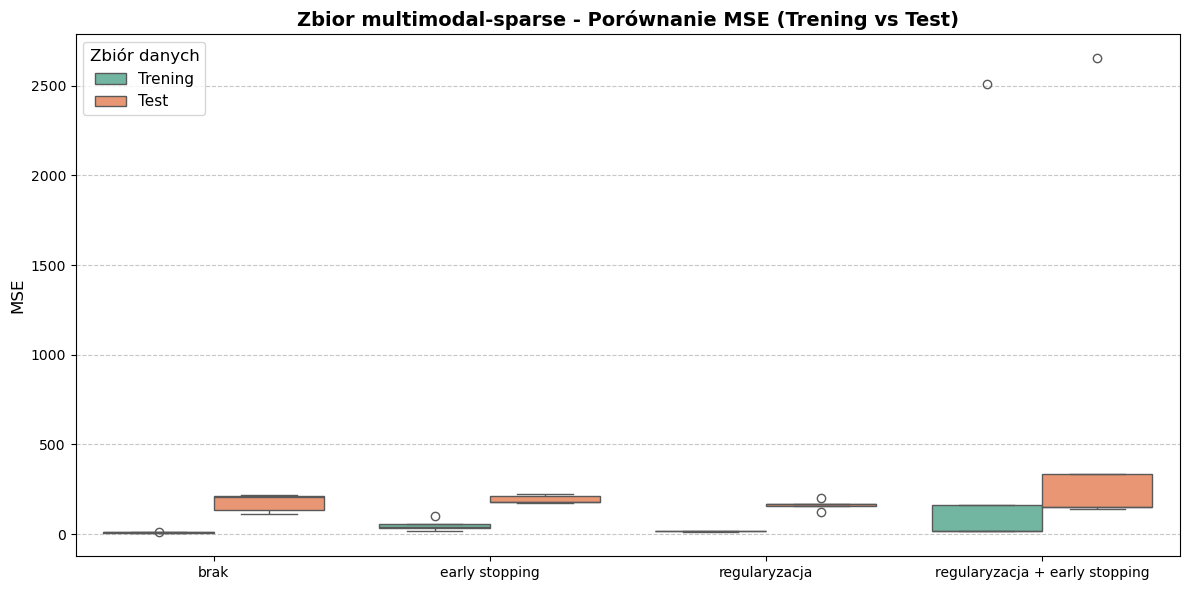

In [227]:
rysuj_boxploty(df_wyniki, "Zbior multimodal-sparse", "MSE")

# Dane rings5-sparse

In [228]:
rings5_sparse_test = pd.read_csv("mio1/classification/rings5-sparse-test.csv")
rings5_sparse_train = pd.read_csv("mio1/classification/rings5-sparse-training.csv")

X_train = rings5_sparse_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings5_sparse_train[['c']].to_numpy().astype(int) 
X_test = rings5_sparse_test[['x', 'y']].to_numpy()
y_test_etykiety = rings5_sparse_test[['c']].to_numpy().astype(int)

X_test, X_val, y_test_etykiety, y_val_etykiety = train_test_split(X_test, y_test_etykiety, test_size=0.2, random_state=123)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)
y_val = to_one_hot(y_val_etykiety, liczba_klas)

In [229]:
df_wyniki = train_N(X_train, y_train, X_val, y_val, X_test, y_test, 
                                  N=5, epoki=10000, rozmiar_batcha=64, k=400, regresja=False)

tabela_podsumowujaca_regularyzacja(df_wyniki)


Rozpoczynam testy: brak
Próba 1/5 | Wykonano epok: 10000 | Score Trening: 0.9091 | Score Test: 0.8025
Próba 2/5 | Wykonano epok: 10000 | Score Trening: 0.8998 | Score Test: 0.8066
Próba 3/5 | Wykonano epok: 10000 | Score Trening: 0.8801 | Score Test: 0.8272
Próba 4/5 | Wykonano epok: 10000 | Score Trening: 0.8808 | Score Test: 0.8109
Próba 5/5 | Wykonano epok: 10000 | Score Trening: 0.8845 | Score Test: 0.7917

Rozpoczynam testy: early stopping
Próba 1/5 | Wykonano epok: 1142 | Score Trening: 0.9292 | Score Test: 0.8098
Próba 2/5 | Wykonano epok: 1079 | Score Trening: 0.8418 | Score Test: 0.8024
Próba 3/5 | Wykonano epok: 1245 | Score Trening: 0.8578 | Score Test: 0.7954
Próba 4/5 | Wykonano epok:  784 | Score Trening: 0.8444 | Score Test: 0.8046
Próba 5/5 | Wykonano epok: 1309 | Score Trening: 0.8937 | Score Test: 0.8419

Rozpoczynam testy: regularyzacja
Próba 1/5 | Wykonano epok: 10000 | Score Trening: 0.9051 | Score Test: 0.7777
Próba 2/5 | Wykonano epok: 10000 | Score Trening: 0.7

Score_Trening         Score_Test          \
                                        mean     std       mean     std   
Konfiguracja                                                              
brak                                  0.8909  0.0130     0.8078  0.0130   
early stopping                        0.8734  0.0375     0.8108  0.0181   
regularyzacja                         0.8747  0.0495     0.7849  0.0347   
regularyzacja + early stopping        0.8869  0.0271     0.8118  0.0255   

                                  Epoki            
                                   mean       std  
Konfiguracja                                       
brak                            10000.0    0.0000  
early stopping                   1111.8  203.7589  
regularyzacja                   10000.0    0.0000  
regularyzacja + early stopping    996.8  143.6200

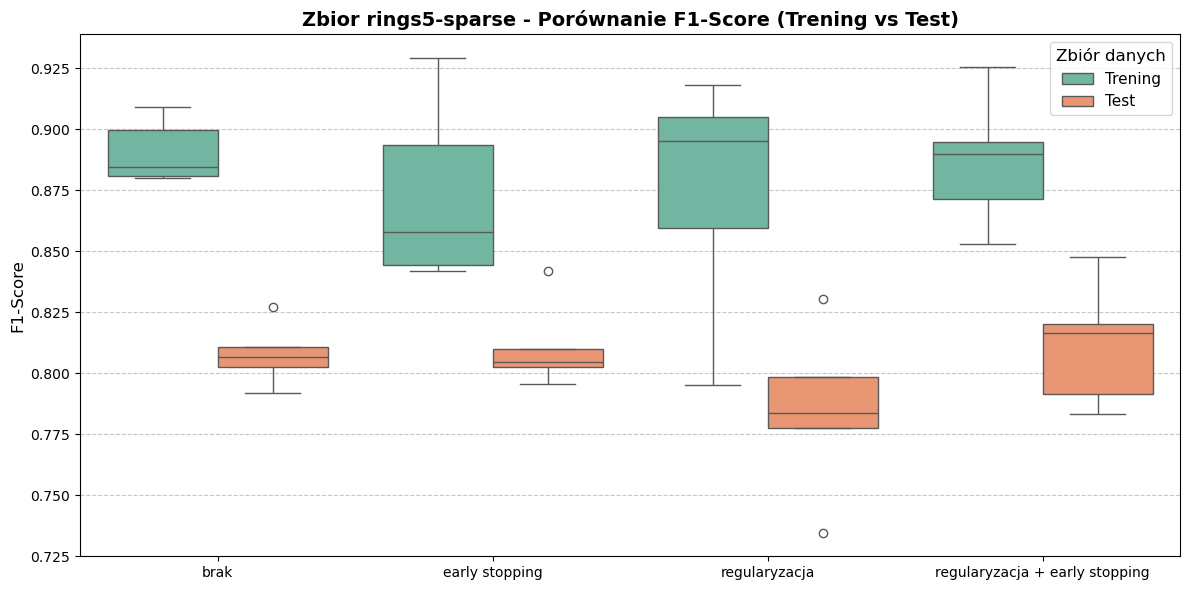

In [230]:
rysuj_boxploty(df_wyniki, "Zbior rings5-sparse", "F1-Score")

# Dane rings3-balance

In [231]:
rings3_balance_test = pd.read_csv("mio1/classification/rings3-balance-test.csv")
rings3_balance_train = pd.read_csv("mio1/classification/rings3-balance-training.csv")

X_train = rings3_balance_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings3_balance_train[['c']].to_numpy().astype(int) 
X_test = rings3_balance_test[['x', 'y']].to_numpy()
y_test_etykiety = rings3_balance_test[['c']].to_numpy().astype(int)

X_test, X_val, y_test_etykiety, y_val_etykiety = train_test_split(X_test, y_test_etykiety, test_size=0.2, random_state=123)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)
y_val = to_one_hot(y_val_etykiety, liczba_klas)

In [232]:
df_wyniki = train_N(X_train, y_train, X_val, y_val, X_test, y_test, 
                                  N=5, epoki=10000, rozmiar_batcha=64, k=400, regresja=False)

tabela_podsumowujaca_regularyzacja(df_wyniki)


Rozpoczynam testy: brak
Próba 1/5 | Wykonano epok: 10000 | Score Trening: 0.8863 | Score Test: 0.8448
Próba 2/5 | Wykonano epok: 10000 | Score Trening: 0.9485 | Score Test: 0.9055
Próba 3/5 | Wykonano epok: 10000 | Score Trening: 0.9071 | Score Test: 0.8557
Próba 4/5 | Wykonano epok: 10000 | Score Trening: 0.9127 | Score Test: 0.8441
Próba 5/5 | Wykonano epok: 10000 | Score Trening: 0.9496 | Score Test: 0.9119

Rozpoczynam testy: early stopping
Próba 1/5 | Wykonano epok: 1109 | Score Trening: 0.8998 | Score Test: 0.8509
Próba 2/5 | Wykonano epok:  919 | Score Trening: 0.9120 | Score Test: 0.8440
Próba 3/5 | Wykonano epok:  902 | Score Trening: 0.9005 | Score Test: 0.8499
Próba 4/5 | Wykonano epok:  849 | Score Trening: 0.8812 | Score Test: 0.8483
Próba 5/5 | Wykonano epok:  461 | Score Trening: 0.9222 | Score Test: 0.8580

Rozpoczynam testy: regularyzacja
Próba 1/5 | Wykonano epok: 10000 | Score Trening: 0.9297 | Score Test: 0.9452
Próba 2/5 | Wykonano epok: 10000 | Score Trening: 0.9

Score_Trening         Score_Test          \
                                        mean     std       mean     std   
Konfiguracja                                                              
brak                                  0.9209  0.0276     0.8724  0.0335   
early stopping                        0.9032  0.0153     0.8502  0.0051   
regularyzacja                         0.9073  0.0237     0.9151  0.0371   
regularyzacja + early stopping        0.9253  0.0168     0.9025  0.0118   

                                  Epoki            
                                   mean       std  
Konfiguracja                                       
brak                            10000.0    0.0000  
early stopping                    848.0  237.6173  
regularyzacja                   10000.0    0.0000  
regularyzacja + early stopping    933.8  281.9445

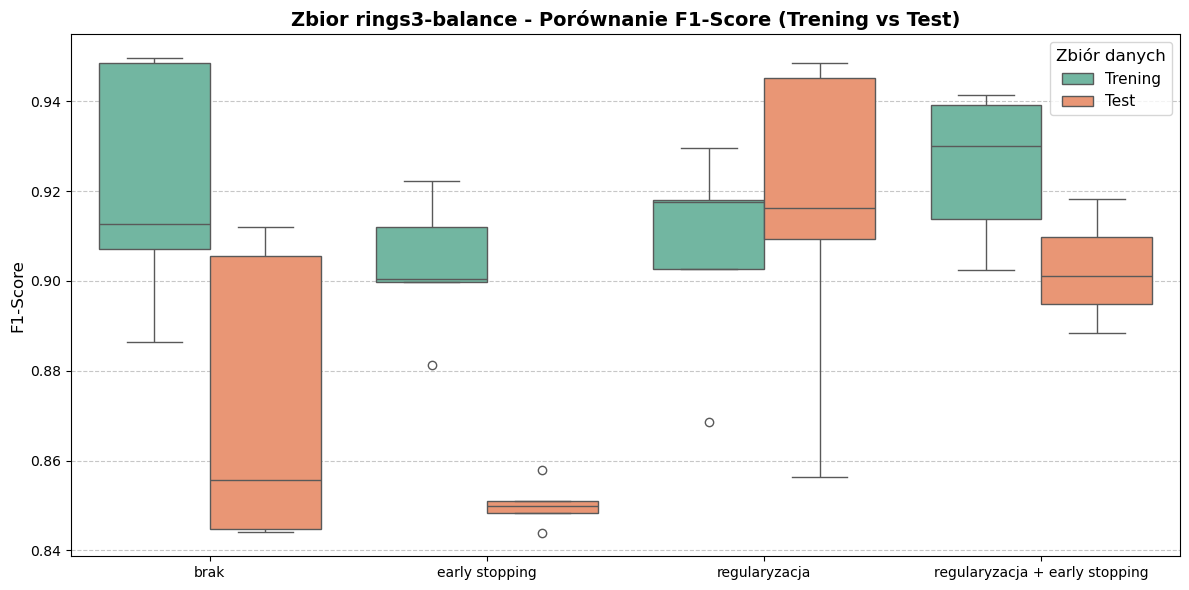

In [233]:
rysuj_boxploty(df_wyniki, "Zbior rings3-balance", "F1-Score")

# Dane xor3-balance

In [234]:
xor3_balance_test = pd.read_csv("mio1/classification/xor3-balance-test.csv")
xor3_balance_train = pd.read_csv("mio1/classification/xor3-balance-training.csv")

X_train = xor3_balance_train[['x', 'y']].to_numpy() 
y_train_etykiety = xor3_balance_train[['c']].to_numpy().astype(int) 
X_test = xor3_balance_test[['x', 'y']].to_numpy()
y_test_etykiety = xor3_balance_test[['c']].to_numpy().astype(int)

X_test, X_val, y_test_etykiety, y_val_etykiety = train_test_split(X_test, y_test_etykiety, test_size=0.2, random_state=123)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)
y_val = to_one_hot(y_val_etykiety, liczba_klas)

In [235]:
df_wyniki = train_N(X_train, y_train, X_val, y_val, X_test, y_test, 
                                  N=5, epoki=10000, rozmiar_batcha=64, k=300, regresja=False)

tabela_podsumowujaca_regularyzacja(df_wyniki)


Rozpoczynam testy: brak
Próba 1/5 | Wykonano epok: 10000 | Score Trening: 0.9838 | Score Test: 0.9236
Próba 2/5 | Wykonano epok: 10000 | Score Trening: 0.9798 | Score Test: 0.9236
Próba 3/5 | Wykonano epok: 10000 | Score Trening: 1.0000 | Score Test: 0.9501
Próba 4/5 | Wykonano epok: 10000 | Score Trening: 0.9782 | Score Test: 0.8981
Próba 5/5 | Wykonano epok: 10000 | Score Trening: 0.9798 | Score Test: 0.9552

Rozpoczynam testy: early stopping
Próba 1/5 | Wykonano epok:  839 | Score Trening: 0.9838 | Score Test: 0.9032
Próba 2/5 | Wykonano epok:  855 | Score Trening: 0.9629 | Score Test: 0.8798
Próba 3/5 | Wykonano epok: 1233 | Score Trening: 0.9947 | Score Test: 0.9385
Próba 4/5 | Wykonano epok: 1161 | Score Trening: 0.9897 | Score Test: 0.9070
Próba 5/5 | Wykonano epok: 1131 | Score Trening: 0.9844 | Score Test: 0.9203

Rozpoczynam testy: regularyzacja
Próba 1/5 | Wykonano epok: 10000 | Score Trening: 0.9649 | Score Test: 0.9056
Próba 2/5 | Wykonano epok: 10000 | Score Trening: 0.9

Score_Trening         Score_Test          \
                                        mean     std       mean     std   
Konfiguracja                                                              
brak                                  0.9843  0.0090     0.9301  0.0231   
early stopping                        0.9831  0.0121     0.9098  0.0217   
regularyzacja                         0.9644  0.0200     0.9268  0.0195   
regularyzacja + early stopping        0.9732  0.0138     0.9069  0.0186   

                                  Epoki            
                                   mean       std  
Konfiguracja                                       
brak                            10000.0    0.0000  
early stopping                   1043.8  183.5244  
regularyzacja                   10000.0    0.0000  
regularyzacja + early stopping   1068.8  214.2795

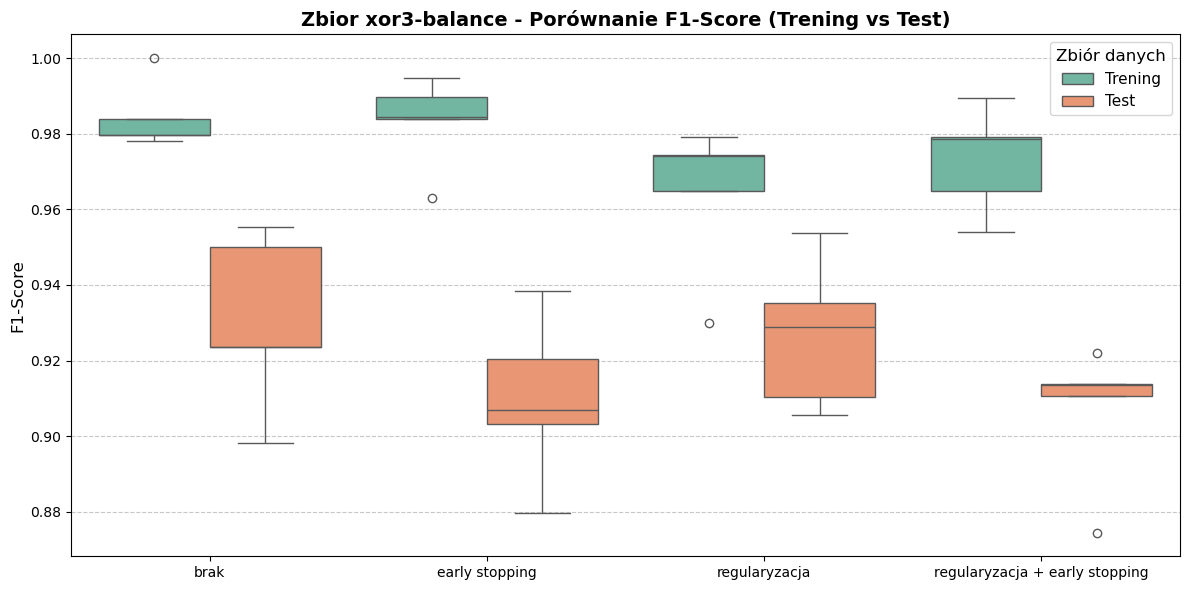

In [236]:
rysuj_boxploty(df_wyniki, "Zbior xor3-balance", "F1-Score")